# Event Feature: City-Wide Daily Regression F-Test

Question: do sports event-day features add **statistically significant** explanatory power for total city-wide daily ride volume on top of calendar + weather + lag controls?

Approach:
1. Aggregate rides to one row per date (city total).
2. Per-day binary features: `event_wrigley`, `event_grf`, `event_uc`, `event_soldier` — 1 if any home game at that venue today.
3. Fit two nested OLS models — base, and base + event features.
4. F-test the joint hypothesis that all event coefficients are zero (`anova_lm`).

## 1. Setup

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.anova import anova_lm
from dotenv import load_dotenv
from divvy_demand.infra.s3_client import S3Client

load_dotenv('../../.env')
s3 = S3Client(env='prod')

## 2. City-wide daily ride totals + weather

In [6]:
station = s3.read_processed('station')
station['date'] = pd.to_datetime(station['date'])
station = station[station['start_station_name'] != 'Outside of Dock']

daily = station.groupby('date')['total_rides'].sum().rename('rides').reset_index()

weather = s3.read_processed('weather/historical')
weather['date'] = pd.to_datetime(weather['date'])
daily = daily.merge(
    weather[['date', 'temp_min_c', 'rain_sum_mm', 'snowfall_sum_cm', 'wind_speed_max_kmh']],
    on='date', how='left',
)
print(f'Daily rows: {len(daily):,}  ({daily["date"].min().date()} → {daily["date"].max().date()})')
daily.head()

Daily rows: 2,249  (2020-01-01 → 2026-02-28)


,date,rides,temp_min_c,rain_sum_mm,snowfall_sum_cm,wind_speed_max_kmh
0,2020-01-01,2141,-6.1,0.0,0.00,35.7
1,2020-01-02,6479,2.5,0.0,0.00,32.7
2,2020-01-03,5890,0.2,0.0,0.00,13.4
3,2020-01-04,3187,-2.0,0.0,1.40,21.8
4,2020-01-05,3035,-4.8,0.0,0.07,36.0


## 3. Pull sports schedules

In [7]:
import requests
from pybaseball import schedule_and_record

# Patch pybaseball numeric coerce (CoW + Arrow string bug)
import pybaseball.team_results as _tr
def _make_numeric_safe(data):
    for col in ['R', 'RA', 'Inn', 'Rank', 'Attendance']:
        data[col] = pd.to_numeric(data[col], errors='coerce')
    return data
_tr.make_numeric = _make_numeric_safe

SEASONS = list(range(2021, 2026))

def mlb_home_dates(team):
    frames = []
    for yr in SEASONS:
        s = schedule_and_record(yr, team)
        s = s[s['Home_Away'] == 'Home'].copy()
        s['season'] = yr
        frames.append(s)
    df = pd.concat(frames, ignore_index=True)
    df['date'] = pd.to_datetime(
        df['Date'].str.replace(r' \(\d+\)', '', regex=True) + ' ' + df['season'].astype(str),
        format='%A, %b %d %Y', errors='coerce',
    )
    return set(df['date'].dropna())

cubs_dates = mlb_home_dates('CHC')
sox_dates  = mlb_home_dates('CHW')
print(f'Cubs: {len(cubs_dates)}   Sox: {len(sox_dates)}')

http://www.baseball-reference.com/teams/CHC/2021-schedule-scores.shtml
http://www.baseball-reference.com/teams/CHC/2022-schedule-scores.shtml


/Users/zimenghuang/Desktop/codes/hobby_projects/Divvy/divvy/.venv/lib/python3.11/site-packages/pybaseball/team_results.py:75: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Attendance'].replace(r'^Unknown$', np.nan, regex=True, inplace = True) # make this a NaN so the column can benumeric
/Users/zimenghuang/Desktop/codes/hobby_pro

http://www.baseball-reference.com/teams/CHC/2023-schedule-scores.shtml


/Users/zimenghuang/Desktop/codes/hobby_projects/Divvy/divvy/.venv/lib/python3.11/site-packages/pybaseball/team_results.py:75: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Attendance'].replace(r'^Unknown$', np.nan, regex=True, inplace = True) # make this a NaN so the column can benumeric


http://www.baseball-reference.com/teams/CHC/2024-schedule-scores.shtml


/Users/zimenghuang/Desktop/codes/hobby_projects/Divvy/divvy/.venv/lib/python3.11/site-packages/pybaseball/team_results.py:75: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Attendance'].replace(r'^Unknown$', np.nan, regex=True, inplace = True) # make this a NaN so the column can benumeric


... (8 outputs left out)

http://www.baseball-reference.com/teams/CHW/2024-schedule-scores.shtml


/Users/zimenghuang/Desktop/codes/hobby_projects/Divvy/divvy/.venv/lib/python3.11/site-packages/pybaseball/team_results.py:75: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Attendance'].replace(r'^Unknown$', np.nan, regex=True, inplace = True) # make this a NaN so the column can benumeric


http://www.baseball-reference.com/teams/CHW/2025-schedule-scores.shtml
Cubs: 392   Sox: 389


/Users/zimenghuang/Desktop/codes/hobby_projects/Divvy/divvy/.venv/lib/python3.11/site-packages/pybaseball/team_results.py:75: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Attendance'].replace(r'^Unknown$', np.nan, regex=True, inplace = True) # make this a NaN so the column can benumeric


In [8]:
# Bears (NFL)
import nfl_data_py as nfl
nfl_sched = nfl.import_schedules(SEASONS)
bears_dates = set(pd.to_datetime(nfl_sched.loc[nfl_sched['home_team'] == 'CHI', 'gameday']))

# Bulls (NBA)
from nba_api.stats.endpoints import leaguegamefinder
BULLS_TEAM_ID = 1610612741
bulls_games = leaguegamefinder.LeagueGameFinder(
    team_id_nullable=BULLS_TEAM_ID, date_from_nullable='01/01/2021',
).get_data_frames()[0]
bulls_home = bulls_games[bulls_games['MATCHUP'].str.contains('vs\\.', regex=True)]
bulls_dates = set(pd.to_datetime(bulls_home['GAME_DATE']))

# Blackhawks (NHL)
hawks_dates = set()
for s in ['20202021','20212022','20222023','20232024','20242025','20252026']:
    games = requests.get(f'https://api-web.nhle.com/v1/club-schedule-season/CHI/{s}').json().get('games', [])
    for g in games:
        if g['homeTeam']['abbrev'] == 'CHI':
            hawks_dates.add(pd.to_datetime(g['gameDate']))

print(f'Bears: {len(bears_dates)}   Bulls: {len(bulls_dates)}   Hawks: {len(hawks_dates)}')

Bears: 44   Bulls: 257   Hawks: 248


## 4. Per-day event flags

In [9]:
daily['event_wrigley'] = daily['date'].isin(cubs_dates).astype(int)
daily['event_grf']     = daily['date'].isin(sox_dates).astype(int)
daily['event_uc']      = daily['date'].isin(bulls_dates | hawks_dates).astype(int)
daily['event_soldier'] = daily['date'].isin(bears_dates).astype(int)

EVENT_COLS = ['event_wrigley', 'event_grf', 'event_uc', 'event_soldier']
print(daily[EVENT_COLS].sum().to_frame('days with event'))

               days with event
event_wrigley              392
event_grf                  389
event_uc                   486
event_soldier               44


## 5. Build regression panel

Controls: lag1 of city rides, weather, day-of-week and month dummies.

In [16]:
daily = daily.sort_values('date').reset_index(drop=True)
daily['lag1_rides'] = daily['rides'].shift(1)
daily['weekday']    = daily['date'].dt.weekday
daily['month']      = daily['date'].dt.month

# Train/val/test cutoffs — same convention as other forecasting notebooks
max_date   = daily['date'].max()
test_start = max_date - pd.DateOffset(years=1) + pd.Timedelta(days=1)
val_start  = max_date - pd.DateOffset(years=2) + pd.Timedelta(days=1)

panel = daily[
    (daily['date'] < val_start)
    & daily['lag1_rides'].notna()
    & daily['temp_min_c'].notna()
].copy()
print(f'Train window: {panel["date"].min().date()} → {panel["date"].max().date()}')
print(f'Panel rows: {len(panel):,}')

Train window: 2020-01-02 → 2024-02-28
Panel rows: 1,517


In [17]:
WEATHER_COLS = ['temp_min_c', 'rain_sum_mm', 'snowfall_sum_cm', 'wind_speed_max_kmh']

dow_dummies   = pd.get_dummies(panel['weekday'], prefix='dow',   drop_first=True).astype(float)
month_dummies = pd.get_dummies(panel['month'],   prefix='month', drop_first=True).astype(float)

X_base = pd.concat([
    panel[['lag1_rides'] + WEATHER_COLS].astype(float),
    dow_dummies,
    month_dummies,
], axis=1)
X_base = sm.add_constant(X_base)

X_full = pd.concat([X_base, panel[EVENT_COLS].astype(float)], axis=1)
y      = panel['rides'].astype(float).values

print(f'X_base: {X_base.shape}    X_full: {X_full.shape}')

X_base: (1517, 23)    X_full: (1517, 27)


## 6. Fit base and full models

In [18]:
model_base = sm.OLS(y, X_base.values).fit()
model_full = sm.OLS(y, X_full.values).fit()

print(f'Base R²:   {model_base.rsquared:.5f}    Adj R²: {model_base.rsquared_adj:.5f}    AIC: {model_base.aic:,.0f}')
print(f'Full R²:   {model_full.rsquared:.5f}    Adj R²: {model_full.rsquared_adj:.5f}    AIC: {model_full.aic:,.0f}')
print(f'ΔR²: {model_full.rsquared - model_base.rsquared:.5f}')

Base R²:   0.86410    Adj R²: 0.86210    AIC: 28,539
Full R²:   0.87682    Adj R²: 0.87467    AIC: 28,398
ΔR²: 0.01272


## 7. F-test: are the event coefficients jointly zero?

H0: β_wrigley = β_grf = β_uc = β_soldier = 0

In [19]:
anova = anova_lm(model_base, model_full)
print(anova)
print()
f_stat = anova.loc[1, 'F']
p_val  = anova.loc[1, 'Pr(>F)']
print(f'Joint F-test: F = {f_stat:.2f},  p = {p_val:.3e}')
print(f'Conclusion: {"REJECT H0 — events significantly improve the model" if p_val < 0.05 else "FAIL TO REJECT H0"}')

   df_resid           ssr  df_diff       ss_diff         F        Pr(>F)
0    1494.0  1.275332e+10      0.0           NaN       NaN           NaN
1    1490.0  1.155974e+10      4.0  1.193586e+09  38.46201  1.138670e-30

Joint F-test: F = 38.46,  p = 1.139e-30
Conclusion: REJECT H0 — events significantly improve the model


## 8. Individual event coefficients

Each is the average extra city-wide rides on a game day, holding everything else constant.

In [20]:
params  = pd.Series(model_full.params,  index=X_full.columns)
tvalues = pd.Series(model_full.tvalues, index=X_full.columns)
pvalues = pd.Series(model_full.pvalues, index=X_full.columns)
se      = pd.Series(model_full.bse,     index=X_full.columns)

summary = pd.DataFrame({
    'coef': params[EVENT_COLS],
    'se':   se[EVENT_COLS],
    't':    tvalues[EVENT_COLS],
    'p':    pvalues[EVENT_COLS],
})
print(summary.round(3))

                   coef       se       t      p
event_wrigley  2574.415  250.493  10.277  0.000
event_grf      2658.945  251.554  10.570  0.000
event_uc        253.665  194.521   1.304  0.192
event_soldier   484.245  592.102   0.818  0.414


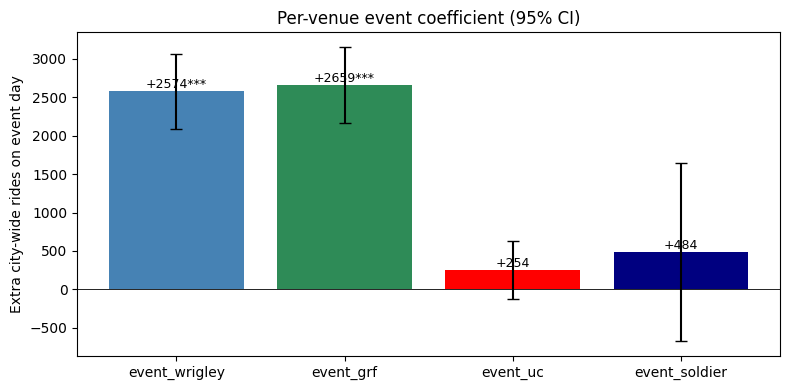

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(summary.index, summary['coef'], yerr=1.96 * summary['se'],
       color=['steelblue', 'seagreen', 'red', 'navy'], capsize=4)
ax.axhline(0, color='black', linewidth=0.6)
ax.set_ylabel('Extra city-wide rides on event day')
ax.set_title('Per-venue event coefficient (95% CI)')
for i, (coef, p) in enumerate(zip(summary['coef'], summary['p'])):
    star = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
    ax.text(i, coef, f'{coef:+.0f}{star}', ha='center', va='bottom' if coef >= 0 else 'top', fontsize=9)
plt.tight_layout()
plt.show()